# Trabalhar com os arquivos

In [2]:
import tarfile
import os

arquivos = [
    "20030228_easy_ham.tar.bz2",
    "20030228_hard_ham.tar.bz2",
    "20030228_spam.tar.bz2"
]

for arquivo in arquivos:
    with tarfile.open(arquivo, "r:bz2") as tar:
        tar.extractall("spamassassin_data")

print(os.listdir("spamassassin_data"))

/tmp/ipykernel_1344/3736658264.py:12: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall("spamassassin_data")


['hard_ham', 'spam', 'easy_ham']


In [3]:
import os

pasta = "spamassassin_data/easy_ham"

arquivos = os.listdir(pasta)

print(arquivos[:5])

['00413.e637d3bed73c6df691dc86dd61d46192', '01926.a39cdccce6bf270df65526eb028cd53f', '02086.cce6b354269ae66f536b1e04b16a4197', '00321.c3dda1549b97568144b8290208504673', '01415.f3a2a0972d0e7c8490bcd79664be7db5']


In [4]:
caminho = os.path.join(pasta, arquivos[0])

with open(caminho, "r", encoding="latin-1") as f:
    email = f.read()

print(email[:3000])

From fork-admin@xent.com  Wed Sep  4 11:41:40 2002
Return-Path: <fork-admin@xent.com>
Delivered-To: yyyy@localhost.spamassassin.taint.org
Received: from localhost (jalapeno [127.0.0.1])
	by jmason.org (Postfix) with ESMTP id D9B4916F7A
	for <jm@localhost>; Wed,  4 Sep 2002 11:40:00 +0100 (IST)
Received: from jalapeno [127.0.0.1]
	by localhost with IMAP (fetchmail-5.9.0)
	for jm@localhost (single-drop); Wed, 04 Sep 2002 11:40:00 +0100 (IST)
Received: from xent.com ([64.161.22.236]) by dogma.slashnull.org
    (8.11.6/8.11.6) with ESMTP id g83LawZ04243 for <jm@jmason.org>;
    Tue, 3 Sep 2002 22:36:58 +0100
Received: from lair.xent.com (localhost [127.0.0.1]) by xent.com (Postfix)
    with ESMTP id A0104294108; Tue,  3 Sep 2002 14:34:02 -0700 (PDT)
Delivered-To: fork@spamassassin.taint.org
Received: from alumnus.caltech.edu (alumnus.caltech.edu [131.215.49.51])
    by xent.com (Postfix) with ESMTP id D675F294099; Tue,  3 Sep 2002 14:33:22
    -0700 (PDT)
Received: from localhost (localhos

## Pré-processamento dos e-mails

Os arquivos contêm mais do que o texto das mensagens: incluem cabeçalhos de transporte, informações de remetentes e destinatários, conteúdo HTML e, em alguns casos, anexos.

O objetivo desta etapa é transformar cada e-mail em um texto formado pelo **assunto e pelo corpo**, que será utilizado posteriormente pelo modelo de classificação.

A limpeza busca reduzir informações desnecessárias e excluir possíveis indicadores produzidos por filtros antispam. Ela preserva o conteúdo textual que pode ajudar o modelo a distinguir mensagens legítimas de spam.

### 1. `limpar_texto(texto)`

Esta função padroniza o texto do assunto e do corpo da mensagem.

**Por que foi criada?**

URLs e endereços de e-mail podem conter identificadores muito específicos. Substituí-los por marcadores permite preservar a informação de que havia um link ou endereço, sem manter todos os seus detalhes.

**O que substitui ou remove?**

- URLs iniciadas por `http://`, `https://` ou `www.` são substituídas pelo marcador `URL`.
- Endereços de e-mail reconhecidos pela expressão regular são substituídos por `EMAIL`.
- Sequências de espaços, tabulações e quebras de linha são reduzidas a um único espaço.
- Espaços no início e no final do texto são removidos.

**O que preserva?**

As demais palavras, números, letras maiúsculas e minúsculas, acentos e pontuação permanecem no texto. A função não aplica lematização, stemming ou remoção de palavras frequentes.

**Exemplo:**

Antes:  
`Acesse https://exemplo.com/oferta e escreva para contato@exemplo.com`

Depois:  
`Acesse URL e escreva para EMAIL`

**Limitação:** essa substituição também descarta informações potencialmente úteis, como o domínio de um link. Trata-se de uma escolha de representação do texto, e não de uma garantia contra vazamento de dados.

### 2. `limpar_assunto(subject)`

Esta função remove determinadas marcações explícitas de spam do assunto e, depois, aplica `limpar_texto()`.

**Por que foi criada?**

Um filtro antispam pode acrescentar marcações ao assunto após analisar uma mensagem. Se o modelo utilizar essas marcações, poderá aprender a reconhecer o resultado de outro filtro em vez de aprender padrões do conteúdo original.

**O que remove?**

A expressão regular procura marcações como:

- `[SPAM]`
- `***SPAM***`
- Outras variações de `spam` cercadas por asteriscos.

A busca ignora diferenças entre maiúsculas e minúsculas.

**O que preserva?**

O restante do assunto é mantido, com URLs, endereços de e-mail e espaços tratados por `limpar_texto()`.

A palavra `spam` usada normalmente em uma frase não é removida apenas por aparecer no assunto.

**Exemplo:**

Antes:  
`[SPAM] Oferta especial disponível hoje`

Depois:  
`Oferta especial disponível hoje`

**Limitação:** a função trata os padrões previstos na expressão regular. Outras marcações podem permanecer. Além disso, uma marcação pode fazer parte de uma discussão legítima sobre spam; sua remoção é uma decisão de pré-processamento.

### 3. `extrair_corpo(msg)`

Esta função extrai o conteúdo textual do corpo do e-mail.

**Por que foi criada?**

Um e-mail pode conter várias partes: texto simples, uma versão em HTML e anexos. Essas partes precisam ser interpretadas antes de formar o texto utilizado pelo modelo.

**Como funciona?**

Quando a mensagem possui múltiplas partes, a função percorre sua estrutura e:

- Ignora partes cujo cabeçalho `Content-Disposition` contém `attachment`.
- Extrai o conteúdo das partes `text/plain`.
- Converte partes `text/html` em texto utilizando `BeautifulSoup`.
- Concatena os textos extraídos, separados por espaços.

Quando a mensagem não possui múltiplas partes, tenta obter diretamente seu conteúdo. Se ele for HTML, também realiza a conversão para texto.

**O que remove ou deixa de aproveitar?**

Na conversão de HTML, a estrutura das tags e seus atributos não são mantidos. Assim, um endereço presente apenas no atributo `href` de um link não é preservado pelo `get_text()`; o texto do link pode permanecer.

No percurso de mensagens multipartes, partes não textuais não são acrescentadas diretamente ao resultado.

**O que preserva?**

O texto extraído das partes aceitas, incluindo frases, números e pontuação. Assinaturas, mensagens anteriores citadas e rodapés podem continuar presentes, pois não existe uma regra específica para removê-los.

**Limitações da implementação atual:**

- As versões em texto simples e HTML são concatenadas. Quando representam o mesmo conteúdo, a mensagem pode ficar duplicada.
- O uso de `except: pass` faz com que algumas falhas de leitura sejam ignoradas sem registro.
- Ignorar uma parte marcada como anexo não garante que todos os seus descendentes sejam ignorados: `msg.walk()` também percorre partes internas.
- No ramo de mensagens não multipartes, não há uma verificação explícita para aceitar somente conteúdo textual.

### 4. `processar_email(caminho)`

Esta função coordena o processamento de um arquivo de e-mail.

**Como funciona?**

1. Abre o arquivo em modo binário.
2. Interpreta sua estrutura com `BytesParser` e `policy.default`.
3. Obtém o cabeçalho `Subject` e aplica `limpar_assunto()`.
4. Extrai o corpo com `extrair_corpo()`.
5. Aplica `limpar_texto()` ao corpo.
6. Une assunto e corpo em uma única string.

A leitura em modo binário permite que o parser interprete as informações de codificação e a estrutura MIME presentes na mensagem.

**Quais informações entram no resultado?**

Somente o assunto tratado e o corpo extraído.

Cabeçalhos como `Received`, `Return-Path`, `Message-ID` e `X-Spam-Status` não são adicionados ao texto final.

Isso acontece porque a função seleciona o assunto e o corpo, e não porque existe uma regra individual para excluir cada cabeçalho.

**Limitação:** informações semelhantes a cabeçalhos ainda podem aparecer dentro do próprio corpo, por exemplo em mensagens encaminhadas.

### 5. `carregar_pasta(pasta, label)`

Esta função percorre uma pasta, processa seus arquivos e associa os textos a uma classe.

**Como funciona?**

- Lista os itens da pasta.
- Ignora itens que não são arquivos.
- Processa cada arquivo com `processar_email()`.
- Adiciona textos não vazios à lista `dados`.
- Exibe uma mensagem caso uma exceção chegue ao seu bloco de tratamento de erros.

Cada registro contém:

| Coluna | Conteúdo |
|---|---|
| `texto` | Assunto e corpo após o processamento |
| `label` | Classe da mensagem: `0` para legítima e `1` para spam |

As pastas `easy_ham` e `hard_ham` recebem a classe `0`. A pasta `spam` recebe a classe `1`.

A classe é determinada pela pasta de origem e armazenada separadamente. Ela não é incluída no texto que será fornecido ao modelo.

**Limitações:** a função não distingue arquivos de e-mail de arquivos auxiliares e não elimina mensagens duplicadas. Além disso, acrescenta registros à lista global `dados`; novas chamadas sem reinicializar essa lista podem repetir registros.

### Relação com data leakage

O vazamento de dados ocorre quando o treinamento ou a avaliação utiliza informações que não estariam legitimamente disponíveis para prever novos exemplos.

Neste processamento, selecionar assunto e corpo evita incluir diretamente cabeçalhos que podem revelar decisões anteriores de filtros antispam. Remover determinadas marcações do assunto também reduz esse risco.

Porém, **a limpeza textual não resolve todas as formas de vazamento**. Nas próximas etapas, será necessário:

- Verificar duplicatas após o processamento, evitando que o mesmo texto apareça no treino e no teste.
- Investigar mensagens muito semelhantes, que podem pertencer à mesma conversa ou campanha.
- Separar treino e teste antes de ajustar transformações que aprendem com os dados.
- Ajustar o vocabulário e os pesos do TF-IDF somente no conjunto de treino.
- Preservar o conjunto de teste para a avaliação final, sem utilizá-lo para escolher modelos ou hiperparâmetros.

As funções atuais aplicam regras fixas e não aprendem estatísticas do conjunto. Por isso, podem ser executadas antes da separação. Já o TF-IDF aprende características do corpus e precisa respeitar essa separação.

In [5]:
import re
from email import policy
from email.parser import BytesParser
from bs4 import BeautifulSoup


def limpar_texto(texto):
    if not texto:
        return ""

    # Remove URLs
    texto = re.sub(r'https?://\S+|www\.\S+', ' URL ', texto)

    # Remove emails
    texto = re.sub(
        r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b',
        ' EMAIL ',
        texto
    )

    # Remove excesso de espaços
    texto = re.sub(r'\s+', ' ', texto)

    return texto.strip()


def limpar_assunto(subject):
    if not subject:
        return ""

    # Remove marcações explícitas de spam
    subject = re.sub(
        r'(\*+\s*spam\s*\*+|\[spam\]|\*\*\*spam\*\*\*)',
        '',
        subject,
        flags=re.IGNORECASE
    )

    return limpar_texto(subject)


def extrair_corpo(msg):
    partes = []

    if msg.is_multipart():

        for parte in msg.walk():

            content_type = parte.get_content_type()
            disposition = str(parte.get("Content-Disposition", ""))

            # Ignora anexos
            if "attachment" in disposition.lower():
                continue

            if content_type == "text/plain":
                try:
                    partes.append(parte.get_content())
                except:
                    pass

            elif content_type == "text/html":
                try:
                    html = parte.get_content()

                    soup = BeautifulSoup(
                        html,
                        "html.parser"
                    )

                    partes.append(
                        soup.get_text(" ")
                    )

                except:
                    pass

    else:

        try:
            conteudo = msg.get_content()

            if msg.get_content_type() == "text/html":

                soup = BeautifulSoup(
                    conteudo,
                    "html.parser"
                )

                conteudo = soup.get_text(" ")

            partes.append(conteudo)

        except:
            pass

    return " ".join(partes)


def processar_email(caminho):

    with open(caminho, "rb") as f:

        msg = BytesParser(
            policy=policy.default
        ).parse(f)

    subject = limpar_assunto(
        msg.get("Subject", "")
    )

    corpo = extrair_corpo(msg)

    corpo = limpar_texto(corpo)

    texto_final = f"{subject} {corpo}"

    return texto_final.strip()

In [6]:
import os
import pandas as pd

dados = []


def carregar_pasta(pasta, label):
    for arquivo in os.listdir(pasta):

        # Ignora o arquivo auxiliar do dataset
        if arquivo == "cmds":
            continue

        caminho = os.path.join(pasta, arquivo)

        if not os.path.isfile(caminho):
            continue

        try:
            texto = processar_email(caminho)

            if texto:
                dados.append({
                    "texto": texto,
                    "label": label
                })

        except Exception as e:
            print(f"Erro em {arquivo}: {e}")


carregar_pasta(
    "spamassassin_data/easy_ham",
    0
)

carregar_pasta(
    "spamassassin_data/hard_ham",
    0
)

carregar_pasta(
    "spamassassin_data/spam",
    1
)


df = pd.DataFrame(dados)

0 = Legitimo
1 = Spam

In [7]:
df.head()

,texto,label
0,"InfoWorld profile of Max Levchin Congrats, in ...",0
1,Plan URL: URL Date: 2002-09-25T10:43:06-05:00 ...,0
2,Colophon 1 URL: URL Date: 2002-10-01T00:11:05-...,0
3,RE: sprint delivers the next big thing?? right...,0
4,Re: Secure Sofware Key Yannick Gingras wrote: ...,0


In [8]:
print(f"Total de e-mails: {len(df)}")

resumo_classes = (
    df["label"]
    .value_counts()
    .rename_axis("label")
    .to_frame("quantidade")
)

resumo_classes["percentual"] = (
    resumo_classes["quantidade"] / len(df) * 100
).round(2)

display(resumo_classes)

print("Valores ausentes:")
display(df.isna().sum())

print(
    "Textos vazios:",
    df["texto"].fillna("").str.strip().eq("").sum()
)

print(
    "Duplicatas de texto:",
    df.duplicated(subset="texto").sum()
)

Total de e-mails: 3250


,quantidade,percentual
label,,
0,2750,84.62
1,500,15.38


Valores ausentes:


,0
texto,0
label,0


Textos vazios: 0
Duplicatas de texto: 53


In [9]:
classes_por_texto = df.groupby("texto")["label"].nunique()

textos_conflitantes = classes_por_texto[
    classes_por_texto > 1
].index

conflitos = df[df["texto"].isin(textos_conflitantes)]

print(f"Textos com classes conflitantes: {len(textos_conflitantes)}")
display(conflitos.head(10))

Textos com classes conflitantes: 0


,texto,label


In [10]:
df = df.dropna(subset=["texto", "label"]).copy()

df = df[df["texto"].str.strip().ne("")]

df = (
    df.drop_duplicates(subset="texto")
    .reset_index(drop=True)
)

print(f"Total após a limpeza: {len(df)}")

Total após a limpeza: 3197


Vamos separar 80% para treino e 20% para testes e usaremos stratify para manter os dados na mesma proporção

In [11]:
from sklearn.model_selection import train_test_split

df_treino, df_teste = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)

df_treino = df_treino.copy()
df_teste = df_teste.copy()

print(f"Treino: {len(df_treino)} e-mails")
print(f"Teste: {len(df_teste)} e-mails")

Treino: 2557 e-mails
Teste: 640 e-mails


In [12]:
sobreposicao = set(df_treino["texto"]) & set(df_teste["texto"])

print(f"Textos idênticos entre treino e teste: {len(sobreposicao)}")

Textos idênticos entre treino e teste: 0


In [13]:
pd.DataFrame({
    "total (%)": df["label"].value_counts(normalize=True) * 100,
    "treino (%)": df_treino["label"].value_counts(normalize=True) * 100,
    "teste (%)": df_teste["label"].value_counts(normalize=True) * 100
}).round(2)

,total (%),treino (%),teste (%)
label,,,
0,85.11,85.1,85.16
1,14.89,14.9,14.84


# SGDClassifier

Nesta etapa, será construído um pipeline com dois componentes: o
`TfidfVectorizer`, responsável por transformar os e-mails em números, e o
`SGDClassifier`, responsável por aprender a distinguir mensagens legítimas
(`0`) de spam (`1`).

### Representação dos textos com TF-IDF

O modelo não trabalha diretamente com frases. Por isso, os textos são
convertidos em uma matriz numérica: cada linha representa um e-mail,
cada coluna representa um termo do vocabulário e cada valor indica o
peso desse termo na mensagem.

O **TF-IDF** combina dois fatores:

- **TF — Term Frequency:** frequência do termo dentro de um e-mail.
- **IDF — Inverse Document Frequency:** atribui menor peso a termos
  presentes em muitos documentos e maior peso aos presentes em poucos.

Assim, um termo repetido em uma mensagem, mas pouco comum no conjunto,
pode receber um peso elevado. Termos ausentes naquela mensagem recebem zero.

Por exemplo, se “reunião” aparece em muitos e-mails e “prêmio” aparece
em poucos, “prêmio” terá um IDF maior. Isso não significa que seja
automaticamente um indicador de spam: **o TF-IDF não utiliza os rótulos
das classes**. Quem aprende essa associação é o classificador.

Na configuração padrão utilizada, o `TfidfVectorizer` também converte
o texto para minúsculas e normaliza cada vetor pela norma L2. Essa
normalização reduz a influência da escala causada pelo comprimento
das mensagens.

Como cada e-mail contém apenas uma pequena parte do vocabulário total,
a maioria dos valores é zero. O resultado é armazenado como uma
**matriz esparsa**, evitando guardar esses zeros explicitamente.

### Classificação com SGDClassifier

O `SGDClassifier` treina um classificador linear utilizando
**descida de gradiente estocástica**, ou SGD. Durante o treinamento,
os pesos do modelo são ajustados progressivamente para reduzir a
função de perda.

Com `loss="log_loss"`, o modelo corresponde a uma **regressão logística
treinada por SGD**. Ele aprende pesos para os termos representados pelo
TF-IDF e combina essas informações para classificar cada mensagem.

Essa abordagem é adequada como modelo inicial por trabalhar de forma
eficiente com matrizes esparsas e um grande número de características.

Os parâmetros definidos são:

| Parâmetro | Função |
|---|---|
| `loss="log_loss"` | Utiliza a perda logística e permite estimar probabilidades das classes. |
| `max_iter=1000` | Define o limite de 1.000 passagens pelos dados de treinamento. |
| `tol=1e-3` | Define a tolerância usada no critério de parada por falta de melhoria. |
| `random_state=42` | Controla a aleatoriedade para facilitar a reprodução dos resultados. |

### Por que utilizar um pipeline?

O `Pipeline` conecta a transformação dos textos ao treinamento do
classificador. Ao ajustar o pipeline, o TF-IDF aprende o vocabulário
e os pesos IDF dos dados de treinamento, e o classificador aprende
a partir da matriz resultante.

Na previsão, os novos e-mails são transformados com o **mesmo
vocabulário e os mesmos pesos IDF**, sem reajustá-los. Termos que
não apareceram no treinamento são ignorados.

Durante a validação cruzada, passar o pipeline completo para a
avaliação permite ajustar o TF-IDF somente na parcela de treino de
cada divisão. Isso evita que o vocabulário e as frequências dos
documentos de validação influenciem o treinamento.

**A célula abaixo apenas define o pipeline.** O aprendizado acontece
quando ele é ajustado com `fit()` ou quando a validação cruzada
ajusta cópias dele em cada divisão.

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier

modelo = Pipeline([
    ("tfidf", TfidfVectorizer()),

    ("classificador", SGDClassifier(
        loss="log_loss",
        max_iter=1000,
        tol=1e-3,
        random_state=42
    ))
])

In [15]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Divide o treino em 5 partes, preservando a proporção das classes
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

resultados = cross_validate(
    modelo,
    df_treino["texto"],
    df_treino["label"],
    cv=cv,
    scoring={
        "precisao": "precision",
        "recall": "recall",
        "f1": "f1"
    },
    n_jobs=-1
)

resumo = pd.DataFrame({
    metrica: {
        "media": resultados[f"test_{metrica}"].mean(),
        "desvio": resultados[f"test_{metrica}"].std()
    }
    for metrica in ["precisao", "recall", "f1"]
}).T

display(resumo.round(4))

,media,desvio
precisao,0.9701,0.0189
recall,0.8478,0.0306
f1,0.9045,0.0208


Matriz de Confusão

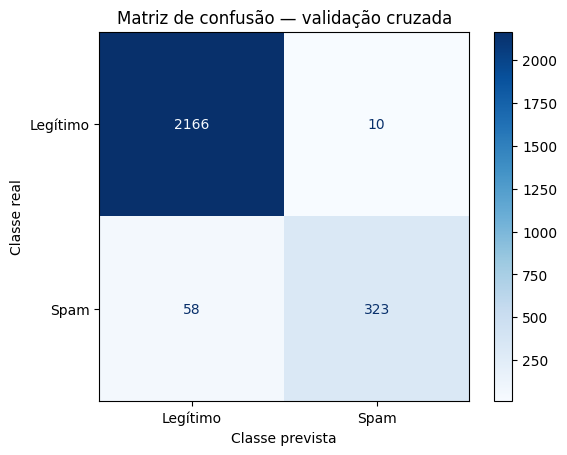

In [16]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

previsoes_cv = cross_val_predict(
    modelo,
    df_treino["texto"],
    df_treino["label"],
    cv=cv,
    method="predict",
    n_jobs=-1
)

ConfusionMatrixDisplay.from_predictions(
    df_treino["label"],
    previsoes_cv,
    labels=[0, 1],
    display_labels=["Legítimo", "Spam"],
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de confusão — validação cruzada")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.show()

### Interpretação da matriz de confusão

A matriz compara as **classes reais, nas linhas**, com as **classes
previstas, nas colunas**. A diagonal principal representa os acertos;
as demais posições representam os erros.

Considerando **spam como classe positiva**, os resultados foram:

| Resultado | Quantidade | Significado |
|---|---:|---|
| Verdadeiros negativos | 2.166 | E-mails legítimos classificados corretamente. |
| Falsos positivos | 10 | E-mails legítimos classificados incorretamente como spam. |
| Falsos negativos | 58 | Spams classificados incorretamente como legítimos. |
| Verdadeiros positivos | 323 | Spams detectados corretamente. |

### O que os resultados mostram?

Dos **2.176 e-mails legítimos**, apenas **10 foram classificados como
spam**, correspondendo a aproximadamente **0,46%** dessa classe.
Esse erro pode fazer uma mensagem importante ser enviada para a
pasta de spam.

Dos **381 spams**, o modelo identificou **323**, mas deixou passar
**58**, aproximadamente **15,22%** dos spams presentes na avaliação.

Portanto, nesta configuração, o modelo apresenta poucos falsos
alarmes, mas ainda deixa passar uma parcela dos e-mails indesejados.

### Métricas calculadas a partir da matriz

- **Precisão:** 323 / (323 + 10) = **97,00%**.
  Entre as mensagens classificadas como spam, essa foi a proporção
  de classificações corretas.
- **Recall:** 323 / (323 + 58) = **84,78%**.
  Entre todos os spams, essa foi a proporção detectada.
- **F1-score:** 2 × 323 / (2 × 323 + 10 + 58) = **90,48%**.
  É a média harmônica entre precisão e recall.

Esses valores foram calculados reunindo as previsões das cinco
divisões. Por isso, podem diferir ligeiramente da média das métricas
calculadas separadamente em cada divisão.

### Como essa avaliação foi realizada?

A matriz reúne **2.557 previsões de validação cruzada**, obtidas
exclusivamente a partir do conjunto de treino. Cada e-mail foi
classificado por um modelo que não utilizou aquele exemplo no
treinamento nem no ajuste do TF-IDF.

O conjunto de teste permanece reservado para a avaliação final.
Assim, estes resultados servem para analisar a configuração inicial
e orientar melhorias, sem representar ainda o desempenho final no teste.

Uma prioridade para os próximos experimentos é **aumentar a detecção
de spam sem elevar excessivamente os falsos positivos**.

In [17]:
# Obtendo as pontuações de spam (scores)
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve
import numpy as np

probabilidades_cv = cross_val_predict(
    modelo,
    df_treino["texto"],
    df_treino["label"],
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]  # Coluna da classe 1: spam

precisoes, recalls, limiares = precision_recall_curve(
    df_treino["label"],
    probabilidades_cv
)

In [18]:
meta_precisao = 0.99

# O último ponto da curva não possui um limiar correspondente
candidatos = np.flatnonzero(
    precisoes[:-1] >= meta_precisao
)

limiar_escolhido = None

if candidatos.size == 0:
    print("Nenhum limiar atingiu a meta de precisão.")
else:
    # Entre os candidatos, escolhe o de maior recall
    indice = candidatos[np.argmax(recalls[:-1][candidatos])]

    limiar_escolhido = float(limiares[indice])

    print(f"Limiar escolhido: {limiar_escolhido:.6f}")
    print(f"Precisão na seleção: {precisoes[indice]:.2%}")
    print(f"Recall na seleção: {recalls[indice]:.2%}")

Limiar escolhido: 0.680203
Precisão na seleção: 99.32%
Recall na seleção: 77.17%


In [19]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    confusion_matrix
)

if limiar_escolhido is not None:
    comparacao = []

    for nome, limiar in [
        ("Padrão", 0.50),
        ("Prioriza precisão", limiar_escolhido)
    ]:
        previsoes = (probabilidades_cv >= limiar).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            df_treino["label"],
            previsoes,
            labels=[0, 1]
        ).ravel()

        comparacao.append({
            "configuracao": nome,
            "limiar": limiar,
            "precisao": precision_score(
                df_treino["label"], previsoes, zero_division=0
            ),
            "recall": recall_score(
                df_treino["label"], previsoes, zero_division=0
            ),
            "legitimos_marcados_spam": fp,
            "spams_nao_detectados": fn,
            "spams_detectados": tp
        })

    display(
        pd.DataFrame(comparacao)
        .set_index("configuracao")
        .round(4)
    )

,limiar,precisao,recall,legitimos_marcados_spam,spams_nao_detectados,spams_detectados
configuracao,,,,,,
Padrão,0.5000,0.9700,0.8478,10,58,323
Prioriza precisão,0.6802,0.9932,0.7717,2,87,294


### Ajuste do limiar para priorizar a precisão

Neste projeto, considera-se mais prejudicial classificar um e-mail
legítimo como spam do que permitir que uma mensagem indesejada
chegue à caixa de entrada. Por isso, o ajuste prioriza a redução
dos **falsos positivos**, buscando maior precisão na classe spam.

O limiar determina a pontuação mínima necessária para classificar
uma mensagem como spam. Ao elevá-lo, o filtro se torna mais exigente,
reduzindo a quantidade de mensagens bloqueadas.

### Como o limiar foi escolhido?

Primeiro, foram obtidas estimativas de probabilidade de spam por
validação cruzada. Cada e-mail recebeu uma pontuação de um pipeline
que não utilizou aquela mensagem no treinamento, incluindo no
ajuste do TF-IDF.

Em seguida, foram calculados os valores de precisão e recall para
diferentes limiares. Entre aqueles que atingiram **precisão de pelo
menos 99%**, foi escolhido o que apresentou **maior recall**.

O limiar selecionado foi aproximadamente **0,680203**, em comparação
com o valor padrão de **0,50**.

Esse limiar não representa a precisão do modelo: ele é o ponto de
corte aplicado à probabilidade estimada. A precisão é calculada
comparando as classificações resultantes com os rótulos reais.

### Comparação dos resultados

| Indicador | Limiar padrão | Limiar ajustado |
|---|---:|---:|
| Limiar | 0,5000 | 0,6802 |
| Precisão | 97,00% | 99,32% |
| Recall | 84,78% | 77,17% |
| E-mails legítimos classificados como spam | 10 | 2 |
| Spams não detectados | 58 | 87 |
| Spams detectados | 323 | 294 |

Com o ajuste, o número de e-mails legítimos classificados como spam
caiu de **10 para 2**, uma redução de **80% nos falsos positivos**.

Em contrapartida, o número de spams não detectados aumentou de
**58 para 87**. Portanto, foram preservados **8 e-mails legítimos
adicionais**, ao custo de deixar passar **29 spams a mais**.

### Interpretação da precisão e do recall

A **precisão de 99,32%** significa que, das **296 mensagens marcadas
como spam**, **294 eram realmente spam** e **2 eram legítimas**.

O **recall de 77,17%** significa que, dos **381 spams existentes**,
**294 foram detectados** e **87 passaram pelo filtro**.

A queda do recall evidencia o custo da decisão: o filtro passa a
bloquear menos mensagens, mas suas classificações como spam são
mais confiáveis neste conjunto.

### Conclusão e limites da análise

O limiar ajustado está alinhado ao objetivo definido: reduzir o
bloqueio indevido de mensagens legítimas, aceitando uma menor
capacidade de detectar spam.

Entretanto, esses resultados foram calculados sobre as mesmas
previsões utilizadas para escolher o limiar. Assim, representam
o desempenho observado durante o ajuste, e não uma avaliação
independente da configuração escolhida.

O próximo passo é fixar o limiar, ajustar o pipeline com todo o
conjunto de treino e avaliar no conjunto de teste reservado.
A precisão de 99,32% não é garantida em novos dados, e o limiar
não deve ser reajustado com base nos resultados do teste.

Limiar aplicado: 0.680203
E-mails avaliados: 640

Precisão: 98.55%
Recall: 71.58%
F1: 82.93%

Legítimos classificados corretamente: 544
Legítimos marcados como spam: 1
Spams não detectados: 27
Spams detectados: 68


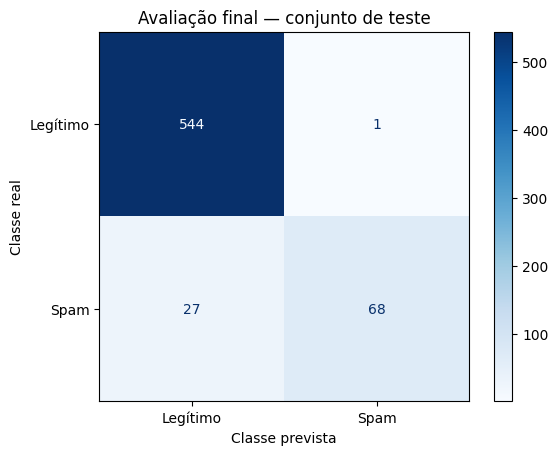

In [20]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Preserva o valor completo do limiar escolhido na validação
limiar_final = limiar_escolhido

if limiar_final is None:
    raise ValueError("É necessário selecionar um limiar antes da avaliação.")

# Aprende o vocabulário, os pesos TF-IDF e o classificador no treino
modelo.fit(
    df_treino["texto"],
    df_treino["label"]
)

# Transforma e classifica o teste sem reajustar o pipeline
probabilidades_teste = modelo.predict_proba(
    df_teste["texto"]
)[:, 1]

previsoes_teste = (
    probabilidades_teste >= limiar_final
).astype(int)

y_teste = df_teste["label"]

tn, fp, fn, tp = confusion_matrix(
    y_teste,
    previsoes_teste,
    labels=[0, 1]
).ravel()

print(f"Limiar aplicado: {limiar_final:.6f}")
print(f"E-mails avaliados: {len(y_teste)}")
print()
print(
    f"Precisão: "
    f"{precision_score(y_teste, previsoes_teste, zero_division=0):.2%}"
)
print(
    f"Recall: "
    f"{recall_score(y_teste, previsoes_teste, zero_division=0):.2%}"
)
print(
    f"F1: "
    f"{f1_score(y_teste, previsoes_teste, zero_division=0):.2%}"
)
print()
print(f"Legítimos classificados corretamente: {tn}")
print(f"Legítimos marcados como spam: {fp}")
print(f"Spams não detectados: {fn}")
print(f"Spams detectados: {tp}")

ConfusionMatrixDisplay.from_predictions(
    y_teste,
    previsoes_teste,
    labels=[0, 1],
    display_labels=["Legítimo", "Spam"],
    cmap="Blues",
    values_format="d"
)

plt.title("Avaliação final — conjunto de teste")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.show()

### Avaliação final no conjunto de teste

Após selecionar o limiar na validação cruzada, o pipeline foi
treinado com todos os dados de treino e avaliado em **640 e-mails
reservados para teste**.

Foi mantido o limiar de aproximadamente **0,680203**, sem realizar
novos ajustes com base nos resultados do teste.

### Resultados obtidos

| Indicador | Resultado |
|---|---:|
| Precisão da classe spam | 98,55% |
| Recall da classe spam | 71,58% |
| F1-score da classe spam | 82,93% |
| Legítimos classificados corretamente | 544 |
| Legítimos classificados como spam | 1 |
| Spams classificados como legítimos | 27 |
| Spams detectados corretamente | 68 |

### Interpretação da matriz de confusão

Dos **545 e-mails legítimos**, o modelo classificou corretamente
**544** e marcou **1** como spam. Isso corresponde a uma
**taxa de falsos positivos de aproximadamente 0,18%**.

Dos **95 spams**, o modelo identificou **68** e deixou passar
**27**. Portanto, **28,42% dos spams não foram detectados**.

Esses resultados mostram um filtro que raramente bloqueou
mensagens legítimas nesta amostra, mas permitiu a passagem de
uma parcela relevante dos spams.

### Interpretação das métricas

A **precisão de 98,55%** significa que, das **69 mensagens
classificadas como spam**, **68 eram realmente spam** e apenas
**1 era legítima**.

O **recall de 71,58%** significa que o modelo detectou **68 dos
95 spams** existentes no conjunto de teste.

O **F1-score de 82,93%** resume precisão e recall por meio da
média harmônica. Como o projeto prioriza evitar o bloqueio
indevido de mensagens legítimas, essa métrica deve ser
interpretada junto à precisão e à quantidade de falsos positivos.

**Precisão e taxa de falsos positivos medem aspectos diferentes:**
a precisão considera todas as mensagens classificadas como spam;
a taxa de falsos positivos considera todos os e-mails realmente
legítimos.

### Comparação com a seleção do limiar

| Métrica | Seleção do limiar na validação cruzada | Teste |
|---|---:|---:|
| Precisão | 99,32% | 98,55% |
| Recall | 77,17% | 71,58% |

A meta de **99% de precisão**, atingida durante a seleção do
limiar, **não foi atingida no teste**. A precisão diminuiu
aproximadamente **0,77 ponto percentual**, enquanto o recall
diminuiu **5,59 pontos percentuais**.

Essa diferença não comprova overfitting por si só. Além de serem
amostras diferentes, os resultados da seleção foram utilizados
para escolher o limiar e podem apresentar otimismo. No teste,
foram apenas **69 previsões de spam**, de modo que poucos erros
já alteram perceptivelmente a precisão.

### Conclusão

O comportamento observado está alinhado à prioridade do projeto:
**reduzir a classificação incorreta de mensagens legítimas como
spam**, aceitando que uma parte dos spams chegue à caixa de entrada.

Entretanto, o resultado não representa ausência de erros nem
garantia de desempenho em outros cenários. A avaliação mede o
desempenho nesta amostra reservada do corpus, não necessariamente
em e-mails atuais, de outros idiomas ou de outras origens.

O pipeline e o limiar serão mantidos como a configuração final
desta versão. Ambos devem ser salvos juntos para reproduzir a
mesma regra de classificação em novas previsões.

In [21]:
assunto = "CONGRATULATIONS! Claim your FREE $1,000,000 prize NOW!"

corpo = """
Dear lucky winner,

You have been selected to receive a guaranteed cash prize of
$1,000,000! This is not a joke. No experience or purchase required!

To claim your money, send your credit card number, bank account
details and password immediately. A small processing fee of $99
is required to release your prize.

ACT NOW! This exclusive offer expires in 24 hours!
Click https://example.com/claim-prize to collect your reward
or contact winner@example.com.

FREE MONEY! GUARANTEED WINNER! LIMITED TIME OFFER!
"""

# Aplica a mesma limpeza usada nos textos de treinamento
texto = f"{limpar_assunto(assunto)} {limpar_texto(corpo)}".strip()

# Localiza a coluna correspondente à classe spam
indice_spam = list(modelo.classes_).index(1)

probabilidade_spam = modelo.predict_proba([texto])[0, indice_spam]
classificacao = int(probabilidade_spam >= limiar_final)

print("Classe esperada: SPAM")
print(f"Probabilidade estimada de spam: {probabilidade_spam:.2%}")
print(f"Limiar aplicado: {limiar_final:.6f}")
print(f"Classificação: {'SPAM' if classificacao == 1 else 'LEGÍTIMO'}")

Classe esperada: SPAM
Probabilidade estimada de spam: 98.34%
Limiar aplicado: 0.680203
Classificação: SPAM


### Teste com um exemplo de spam

Foi criado um e-mail fictício com sinais comuns de spam, como promessa
de prêmio, urgência, solicitação de dados sensíveis e cobrança antecipada.

O assunto e o corpo passam pelas mesmas funções de limpeza utilizadas
no treinamento. Em seguida, o pipeline transforma o texto com o TF-IDF
já ajustado e estima a probabilidade de spam.

Se essa estimativa for maior ou igual ao limiar escolhido
(aproximadamente **0,680203**), a mensagem será classificada como
**spam**; caso contrário, como **legítima**.

Esse exemplo demonstra o uso do modelo em uma nova mensagem, sem
treiná-lo novamente. Por ser um teste isolado com texto fictício,
não substitui a avaliação no conjunto de teste.

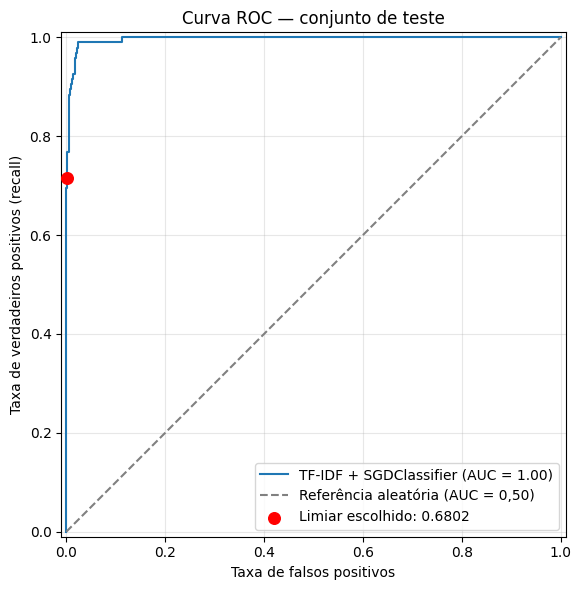

In [22]:
from sklearn.metrics import RocCurveDisplay, confusion_matrix
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_teste,
    probabilidades_teste,
    name="TF-IDF + SGDClassifier",
    ax=ax
)

# Referência de um classificador aleatório
ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Referência aleatória (AUC = 0,50)"
)

# Destaca o ponto correspondente ao limiar já escolhido
tn, fp, fn, tp = confusion_matrix(
    y_teste,
    previsoes_teste,
    labels=[0, 1]
).ravel()

taxa_falsos_positivos = fp / (fp + tn)
taxa_verdadeiros_positivos = tp / (tp + fn)

ax.scatter(
    taxa_falsos_positivos,
    taxa_verdadeiros_positivos,
    color="red",
    s=70,
    zorder=5,
    label=f"Limiar escolhido: {limiar_final:.4f}"
)

ax.set_title("Curva ROC — conjunto de teste")
ax.set_xlabel("Taxa de falsos positivos")
ax.set_ylabel("Taxa de verdadeiros positivos (recall)")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Experimento: priorizando a detecção de spam

Na configuração anterior, priorizamos a precisão para reduzir o
bloqueio indevido de mensagens legítimas. Neste experimento, vamos
avaliar uma prioridade diferente: deixar passar o menor número
possível de spams, aceitando mais falsos positivos.

Para isso, utilizaremos as mesmas pontuações obtidas por validação
cruzada, alterando apenas o limiar de decisão. Não será necessário
treinar outro modelo nesta etapa.

A meta será atingir **recall de pelo menos 99%** nas previsões da
validação cruzada. Entre os limiares que atingirem essa meta,
escolheremos o de **maior precisão**. Em caso de empate, será
priorizado o maior recall.

A comparação mostrará quantos spams adicionais são detectados e
quantos e-mails legítimos passam a ser classificados como spam.

Este experimento utiliza rótulos de spam e mensagens legítimas.
Portanto, não permite concluir que o modelo detecta golpes ou
phishing especificamente. Para esse objetivo, seriam necessários
dados rotulados para essas categorias.

Os resultados serão usados para análise e seleção do limiar.
A meta de recall não representa uma garantia em novas mensagens.
Como o conjunto de teste já foi avaliado, ele não será usado para
orientar essa nova escolha; uma confirmação independente exigiria
novos dados reservados.

In [23]:
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    confusion_matrix
)
import pandas as pd

# Reutiliza as pontuações de validação cruzada já calculadas
precisoes, recalls, limiares = precision_recall_curve(
    df_treino["label"],
    probabilidades_cv
)

# O último ponto da curva não possui limiar correspondente
opcoes = pd.DataFrame({
    "limiar": limiares,
    "precisao": precisoes[:-1],
    "recall": recalls[:-1]
})

meta_recall = 0.99

candidatos = opcoes[
    opcoes["recall"] >= meta_recall
]

limiar_recall = None

if candidatos.empty:
    print("Nenhum limiar atingiu a meta de recall.")
else:
    escolhido = candidatos.sort_values(
        ["precisao", "recall", "limiar"],
        ascending=[False, False, False]
    ).iloc[0]

    limiar_recall = float(escolhido["limiar"])

    print(f"Limiar para priorizar recall: {limiar_recall:.6f}")
    print(f"Precisão na seleção: {escolhido['precisao']:.2%}")
    print(f"Recall na seleção: {escolhido['recall']:.2%}")

    comparacao = []

    for nome, limiar in [
        ("Padrão", 0.50),
        ("Prioriza precisão", limiar_final),
        ("Prioriza recall", limiar_recall)
    ]:
        previsoes = (probabilidades_cv >= limiar).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            df_treino["label"],
            previsoes,
            labels=[0, 1]
        ).ravel()

        comparacao.append({
            "configuracao": nome,
            "limiar": limiar,
            "precisao": precision_score(
                df_treino["label"], previsoes, zero_division=0
            ),
            "recall": recall_score(
                df_treino["label"], previsoes, zero_division=0
            ),
            "legitimos_marcados_spam": fp,
            "spams_nao_detectados": fn,
            "spams_detectados": tp
        })

    display(
        pd.DataFrame(comparacao)
        .set_index("configuracao")
        .round(4)
    )

Limiar para priorizar recall: 0.080886
Precisão na seleção: 69.49%
Recall na seleção: 99.21%


,limiar,precisao,recall,legitimos_marcados_spam,spams_nao_detectados,spams_detectados
configuracao,,,,,,
Padrão,0.5000,0.9700,0.8478,10,58,323
Prioriza precisão,0.6802,0.9932,0.7717,2,87,294
Prioriza recall,0.0809,0.6949,0.9921,166,3,378


### Interpretação do experimento com foco em recall

Ao reduzir o limiar de aproximadamente **0,6802 para 0,0809**,
o filtro passou a exigir uma pontuação menor para classificar
uma mensagem como spam. O modelo não foi treinado novamente:
apenas a regra de decisão foi alterada.

A configuração atingiu **99,21% de recall** nas previsões da
validação cruzada, detectando **378 dos 381 spams** e deixando
passar apenas **3**.

Entretanto, essa maior detecção veio acompanhada de mais falsos
positivos: **166 e-mails legítimos foram classificados como spam**.

| Indicador | Prioriza precisão | Prioriza recall |
|---|---:|---:|
| Limiar | 0,6802 | 0,0809 |
| Precisão | 99,32% | 69,49% |
| Recall | 77,17% | 99,21% |
| Legítimos classificados como spam | 2 | 166 |
| Spams não detectados | 87 | 3 |
| Spams detectados | 294 | 378 |

Em comparação com a configuração que prioriza precisão, foram
detectados **84 spams adicionais**, ao custo de classificar
incorretamente **164 mensagens legítimas adicionais**.

### O que significa a precisão de 69,49%?

Das **544 mensagens classificadas como spam**, **378 eram spam**
e **166 eram legítimas**. Portanto, aproximadamente **30,51% das
mensagens sinalizadas eram falsos alarmes**.

Isso não significa que 30,51% de todos os e-mails legítimos foram
bloqueados. Entre os **2.176 legítimos**, os 166 falsos positivos
representam aproximadamente **7,63%**.

### Quando faria sentido priorizar recall?

Essa estratégia faz sentido quando deixar uma ameaça passar tem
um custo maior do que encaminhar uma mensagem legítima para
verificação adicional.

Alguns contextos possíveis são:

- **Triagem de segurança:** sinalizar mensagens suspeitas para
  análise humana ou por outro sistema.
- **Quarentena recuperável:** reter temporariamente mensagens,
  permitindo sua revisão e liberação.
- **Detecção de golpes ou phishing:** buscar alta detecção quando
  uma mensagem maliciosa não identificada pode causar prejuízo.
  Nesse caso, seria necessário treinar e avaliar com rótulos
  específicos de fraude ou phishing.

A revisão também tem um custo: quanto mais falsos positivos,
maior o trabalho para verificar mensagens legítimas. Portanto,
é necessário considerar a capacidade de revisão e o impacto
dos atrasos na entrega.

### Quando essa configuração seria inadequada?

Ela seria problemática para **excluir mensagens automaticamente
e de forma definitiva**, pois descartaria uma quantidade relevante
de e-mails legítimos.

Também pode ser inadequada quando mensagens importantes precisam
chegar imediatamente e não existe um processo eficiente de revisão.

### Conclusão

Priorizar recall torna o filtro mais abrangente na sinalização de
spam, mas reduz a confiabilidade de cada alerta. A escolha depende
do custo de deixar um spam passar, do custo de bloquear um legítimo
e da ação tomada após a classificação.

Neste experimento, o modelo continua sendo um classificador de
**spam**, não um detector validado de golpes. Os resultados foram
obtidos nas mesmas previsões usadas para selecionar o limiar e
não garantem recall de 99,21% em novas mensagens.

In [27]:
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import json
import platform
import shutil

import cloudpickle
import joblib
import numpy as np

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
from sklearn.utils.validation import check_is_fitted


# 1. Verificações
check_is_fitted(modelo.named_steps["tfidf"])
check_is_fitted(modelo.named_steps["classificador"])

if limiar_final is None or limiar_recall is None:
    raise ValueError("Selecione os dois limiares antes de salvar.")

# Pasta própria para não sobrescrever exportações anteriores
identificador = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
pasta = Path(f"spam_classifier_{identificador}")
pasta.mkdir(parents=True, exist_ok=False)


# 2. Salva as duas configurações
configuracoes = {
    "precisao": float(limiar_final),
    "recall": float(limiar_recall)
}

for nome, limiar in configuracoes.items():
    pacote = {
        "pipeline": modelo,
        "limiar": limiar,
        "classe_positiva": 1,
        "rotulos": {0: "legitimo", 1: "spam"},
        "configuracao": nome,
        "entrada": "assunto e corpo tratados pelo preprocessamento",
        "versao_artefato": 1
    }

    joblib.dump(
        pacote,
        pasta / f"spam_{nome}.joblib",
        compress=3
    )


# 3. Preserva as funções de pré-processamento do notebook
# Necessárias porque a limpeza ocorre fora do Pipeline.
funcoes = {
    "limpar_texto": limpar_texto,
    "limpar_assunto": limpar_assunto,
    "extrair_corpo": extrair_corpo,
    "processar_email": processar_email
}

with (pasta / "preprocessamento.pkl").open("wb") as arquivo:
    cloudpickle.dump(funcoes, arquivo)


# 4. Registra as versões do ambiente
bibliotecas = [
    "numpy",
    "scipy",
    "pandas",
    "scikit-learn",
    "joblib",
    "cloudpickle",
    "beautifulsoup4"
]

versoes = {
    biblioteca: version(biblioteca)
    for biblioteca in bibliotecas
}

(pasta / "requirements.txt").write_text(
    "\n".join(
        f"{biblioteca}=={versao}"
        for biblioteca, versao in versoes.items()
    ) + "\n",
    encoding="utf-8"
)


# 5. Registra métricas e contexto da avaliação
def resumir_metricas(y_real, y_previsto):
    tn, fp, fn, tp = confusion_matrix(
        y_real, y_previsto, labels=[0, 1]
    ).ravel()

    return {
        "quantidade": int(len(y_real)),
        "precisao": float(
            precision_score(y_real, y_previsto, zero_division=0)
        ),
        "recall": float(
            recall_score(y_real, y_previsto, zero_division=0)
        ),
        "f1": float(
            f1_score(y_real, y_previsto, zero_division=0)
        ),
        "verdadeiros_negativos": int(tn),
        "falsos_positivos": int(fp),
        "falsos_negativos": int(fn),
        "verdadeiros_positivos": int(tp)
    }


metricas_selecao = {}

for nome, limiar in configuracoes.items():
    previsoes = (
        np.asarray(probabilidades_cv) >= limiar
    ).astype(int)

    metricas_selecao[nome] = resumir_metricas(
        df_treino["label"],
        previsoes
    )

# Reutiliza o teste já realizado, sem avaliar uma nova configuração
metricas_teste_precisao = resumir_metricas(
    y_teste,
    (
        np.asarray(probabilidades_teste) >= limiar_final
    ).astype(int)
)

metadados = {
    "criado_em_utc": datetime.now(timezone.utc).isoformat(),
    "python": platform.python_version(),
    "bibliotecas": versoes,
    "dataset": "SpamAssassin: easy_ham, hard_ham e spam",
    "quantidade_treino": int(len(df_treino)),
    "quantidade_teste": int(len(df_teste)),
    "limiares": configuracoes,
    "metas_na_selecao": {
        "precisao_minima": 0.99,
        "recall_minimo": 0.99
    },
    "metricas_selecao_cv": metricas_selecao,
    "metricas_teste": {
        "precisao": metricas_teste_precisao,
        "recall": None
    },
    "observacoes": [
        "As duas configuracoes usam o mesmo pipeline treinado.",
        "O pipeline foi ajustado somente no conjunto de treino.",
        "As metricas de selecao usam os dados que escolheram os limiares.",
        "A configuracao de recall nao recebeu avaliacao independente.",
        "Os rotulos representam spam, nao golpes especificamente.",
        "Novas entradas devem receber o mesmo preprocessamento."
    ]
}

(pasta / "metadados.json").write_text(
    json.dumps(metadados, ensure_ascii=False, indent=2),
    encoding="utf-8"
)


# 6. Cria um script para carregar e usar os arquivos
codigo_uso = '''
from pathlib import Path
import cloudpickle
import joblib

PASTA = Path(__file__).resolve().parent


def carregar(configuracao="precisao"):
    if configuracao not in {"precisao", "recall"}:
        raise ValueError("Use 'precisao' ou 'recall'.")

    pacote = joblib.load(PASTA / f"spam_{configuracao}.joblib")

    with (PASTA / "preprocessamento.pkl").open("rb") as arquivo:
        funcoes = cloudpickle.load(arquivo)

    return pacote, funcoes


def prever_texto_processado(texto, pacote):
    if not texto.strip():
        raise ValueError("O texto ficou vazio após o processamento.")

    pipeline = pacote["pipeline"]
    indice = list(pipeline.classes_).index(pacote["classe_positiva"])

    probabilidade = float(
        pipeline.predict_proba([texto])[0, indice]
    )

    classe = int(probabilidade >= pacote["limiar"])

    return {
        "classe": classe,
        "rotulo": pacote["rotulos"][classe],
        "probabilidade_spam": probabilidade,
        "limiar": pacote["limiar"],
        "configuracao": pacote["configuracao"]
    }


def classificar(assunto, corpo, pacote, funcoes):
    texto = (
        f"{funcoes['limpar_assunto'](assunto)} "
        f"{funcoes['limpar_texto'](corpo)}"
    ).strip()

    return prever_texto_processado(texto, pacote)


def classificar_arquivo(caminho, pacote, funcoes):
    texto = funcoes["processar_email"](caminho)
    return prever_texto_processado(texto, pacote)


if __name__ == "__main__":
    pacote, funcoes = carregar("precisao")

    resultado = classificar(
        assunto="Meeting tomorrow",
        corpo="Hi team, our project meeting is tomorrow at 10 AM.",
        pacote=pacote,
        funcoes=funcoes
    )

    print(resultado)
'''

(pasta / "usar_modelo.py").write_text(
    codigo_uso.strip() + "\n",
    encoding="utf-8"
)

1710

In [28]:
# Verifica se os modelos salvos reproduzem as previsões
amostra = df_treino["texto"].iloc[:10]

for nome in configuracoes:
    restaurado = joblib.load(pasta / f"spam_{nome}.joblib")

    np.testing.assert_allclose(
        modelo.predict_proba(amostra),
        restaurado["pipeline"].predict_proba(amostra)
    )

    assert restaurado["limiar"] == configuracoes[nome]

print("Modelos e limiares verificados.")

# Lista os arquivos salvos
for caminho in sorted(pasta.iterdir()):
    print(f"- {caminho.name}")

# Cria o ZIP
arquivo_zip = shutil.make_archive(
    str(pasta),
    "zip",
    root_dir=pasta.parent,
    base_dir=pasta.name
)

print(f"\nZIP criado: {arquivo_zip}")

# Baixa no Colab
from google.colab import files

files.download(arquivo_zip)

Modelos e limiares verificados.
- metadados.json
- preprocessamento.pkl
- requirements.txt
- spam_precisao.joblib
- spam_recall.joblib
- usar_modelo.py

ZIP criado: /content/spam_classifier_20261006_173258_263833.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>